In [4]:
import matplotlib.pyplot as plt
import numpy as np

In [9]:
FOUNDATIONS = ["care", "harm", "fairness", "cheating", "loyalty", "betrayal",
               "authority", "subversion", "purity", "degradation"]

In [ ]:
# step 1(a): import moralBERT from huggingface

In [3]:
!pip install -q torch transformers huggingface_hub pandas openpyxl

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from transformers import AutoModel, AutoTokenizer
from huggingface_hub import PyTorchModelHubMixin

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

Using device: cuda


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [3]:
class MyModel(nn.Module, PyTorchModelHubMixin):
    def __init__(self, bert_model, moral_label=2):
        super().__init__()
        self.bert = bert_model
        self.invariant_trans = nn.Linear(768, 768)
        self.moral_classification = nn.Sequential(
            nn.Linear(768, 768), nn.ReLU(), nn.Linear(768, moral_label)
        )

    def forward(self, input_ids, token_type_ids, attention_mask):
        pooled = self.bert(input_ids,
                           token_type_ids=token_type_ids,
                           attention_mask=attention_mask).last_hidden_state[:, 0, :]
        pooled = self.invariant_trans(pooled)
        return self.moral_classification(pooled)


def preprocessing(texts, tokenizer):
    return tokenizer(texts, add_special_tokens=True, max_length=150,
                     padding="max_length", truncation=True,
                     return_attention_mask=True, return_token_type_ids=True,
                     return_tensors="pt")

In [4]:
_cache = {}
def load_moral_model(mft, content_type="text"):
    key = (mft, content_type)
    if key not in _cache:
        repo = f"vjosap/moralBERT-predict-{mft}-in-{content_type}"
        bert = AutoModel.from_pretrained("bert-base-uncased")  # fresh backbone per model
        _cache[key] = MyModel.from_pretrained(repo, bert_model=bert).to(device).eval()
    return _cache[key]


@torch.no_grad()
def score(texts, mft, content_type="text", batch_size=32):
    model = load_moral_model(mft, content_type)
    probs = []
    for i in range(0, len(texts), batch_size):
        enc = preprocessing(texts[i:i + batch_size], tokenizer)
        enc = {k: v.to(device) for k, v in enc.items()}
        probs.extend(F.softmax(model(**enc), dim=1)[:, 1].cpu().tolist())
    return probs


def predict_morals(texts, content_type="text", foundations=FOUNDATIONS):
    texts = [str(t) for t in texts]
    out = pd.DataFrame({"text": texts})
    for mft in foundations:
        print("Scoring:", mft)
        out[mft] = score(texts, mft, content_type)
    return out

In [5]:
# pass df through moralbert and add 10 foundation probabilities + 0/1 to df as new columns
def append_moralbert(df, text_col="text", content_type="text", threshold=0.5, prefix="mb_"):
    preds = predict_morals(df[text_col].tolist(), content_type) # run prediction
    preds.index = df.index

    out = df.copy()
    for m in FOUNDATIONS:
        out[f"{prefix}{m}"] = preds[m]                                # probability
        out[f"{prefix}{m}_bin"] = (preds[m] >= threshold).astype(int)  # 0/1 based on default 0.5 threshold for now

    out[f"{prefix}foundation"] = preds[FOUNDATIONS].apply(
        lambda row: ", ".join(m for m in FOUNDATIONS if row[m] >= threshold) or "none",
        axis=1,
    )
    return out

In [ ]:
# step 2: append foundation probabilities + labels to our toxicity samples (4 bins of toxicity level with 5000 comments/bin)

In [13]:
toxicity_samples = pd.read_csv("/content/drive/MyDrive/CS74-civilcomments/toxicity_samples.csv")
toxicity_samples.shape

(20000, 47)

In [9]:
toxicity_samples.columns

Index(['id', 'comment_text', 'split', 'created_date', 'publication_id',
       'parent_id', 'article_id', 'rating', 'funny', 'wow', 'sad', 'likes',
       'disagree', 'toxicity', 'severe_toxicity', 'obscene', 'sexual_explicit',
       'identity_attack', 'insult', 'threat', 'male', 'female', 'transgender',
       'other_gender', 'heterosexual', 'homosexual_gay_or_lesbian', 'bisexual',
       'other_sexual_orientation', 'christian', 'jewish', 'muslim', 'hindu',
       'buddhist', 'atheist', 'other_religion', 'black', 'white', 'asian',
       'latino', 'other_race_or_ethnicity', 'physical_disability',
       'intellectual_or_learning_disability', 'psychiatric_or_mental_illness',
       'other_disability', 'identity_annotator_count',
       'toxicity_annotator_count', 'tox_bin'],
      dtype='object')

In [10]:
# ran out of gpu use on this account so I had to run this step on another google account and upload the csv result separately
toxicity_mb = append_moralbert(toxicity_samples, text_col='comment_text')

Scoring: care


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


config.json:   0%|          | 0.00/22.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

KeyboardInterrupt: 

In [5]:
toxicity_mb = pd.read_csv('/content/drive/MyDrive/CS74-civilcomments/toxicity_samples_moralbert.csv')

In [7]:
# overview of moralbert scoring and classification
cols = [f"mb_{m}" for m in FOUNDATIONS]
s = toxicity_mb[cols]

summary = pd.DataFrame({
    "mean": s.mean(),
    "median": s.median(),
    "max": s.max(),
    "share < 0.01": (s < 0.01).mean(),
    "share ≥ 0.1": (s >= 0.1).mean(),
    "share ≥ 0.5": (s >= 0.5).mean(),
    "n ≥ 0.5": (s >= 0.5).sum(),
    "unique values": s.nunique(),
})
summary.index = FOUNDATIONS
summary

,mean,median,max,share < 0.01,share ≥ 0.1,share ≥ 0.5,n ≥ 0.5,unique values
care,0.105508,0.030841,0.979260,0.08260,0.24440,0.05675,1135,19976
harm,0.085765,0.002089,0.993151,0.72985,0.13640,0.07820,1564,19970
fairness,0.073400,0.000919,0.996564,0.79745,0.11500,0.06775,1355,19963
cheating,0.087654,0.001793,0.998007,0.73615,0.13705,0.07990,1598,19973
loyalty,0.013321,0.001223,0.997424,0.93995,0.02050,0.00940,188,19927
betrayal,0.017902,0.000841,0.997705,0.92515,0.02790,0.01375,275,19964
authority,0.059394,0.001186,0.998107,0.80770,0.09640,0.05230,1046,19966
subversion,0.048549,0.001193,0.996639,0.85070,0.07510,0.04415,883,19963
purity,0.011893,0.000711,0.992018,0.96080,0.01890,0.00990,198,19940
degradation,0.069620,0.013899,0.978539,0.31890,0.12480,0.04350,870,19949


In [ ]:
# step 3: analyze foundations vs. toxicity scores

In [ ]:
# experiment(a): use spearman to check agreement between toxicity level and scores for each foundation:
#   i.e. find which foundations track toxicity and how strongly

In [8]:
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

rows = []
for m in FOUNDATIONS:
    rho, p = spearmanr(toxicity_mb[f"mb_{m}"], toxicity_mb["toxicity"])
    rows.append({"foundation": m, "rho": rho, "p": p})
corr = pd.DataFrame(rows)
# use Holm to adjust the p-values so that overall chance of a false positive across all 10 tests stays at 5%
corr["p_holm"] = multipletests(corr["p"], method="holm")[1]
corr.sort_values("rho", ascending=False)

,foundation,rho,p,p_holm
9,degradation,0.285914,0.000000e+00,0.000000e+00
1,harm,0.212915,9.165041e-204,8.248536e-203
3,cheating,0.193701,2.496157e-168,1.996925e-167
8,purity,0.153506,1.029240e-105,7.204682e-105
7,subversion,0.136837,3.408998e-84,2.045399e-83
6,authority,0.050877,6.049379e-13,3.024689e-12
5,betrayal,0.046659,4.064868e-11,1.625947e-10
0,care,0.042193,2.382285e-09,7.146856e-09
4,loyalty,0.012757,7.121364e-02,7.121364e-02
2,fairness,-0.038156,6.751409e-08,1.350282e-07


In [ ]:
# experiment(b): comparing foundation detection rates across bin

In [9]:
from scipy.stats import kruskal, chi2_contingency

by_bin = toxicity_mb.groupby("tox_bin")[[f"mb_{m}_bin" for m in FOUNDATIONS]].mean()
by_bin.columns = FOUNDATIONS
by_bin  # share of comments flagged/foundation, for each toxicity bin

for m in FOUNDATIONS:
    groups = [g[f"mb_{m}"] for _, g in toxicity_mb.groupby("tox_bin")]
    H, p_kw = kruskal(*groups)
    chi2, p_chi, _, _ = chi2_contingency(pd.crosstab(toxicity_mb["tox_bin"], toxicity_mb[f"mb_{m}_bin"]))
    print(f"{m:12s} Kruskal p={p_kw:.2e}  chi2 p={p_chi:.2e}")

care         Kruskal p=2.98e-23  chi2 p=2.65e-05
harm         Kruskal p=2.68e-197  chi2 p=1.08e-60
fairness     Kruskal p=2.34e-10  chi2 p=1.73e-01
cheating     Kruskal p=1.26e-165  chi2 p=4.77e-51
loyalty      Kruskal p=5.88e-13  chi2 p=3.65e-01
betrayal     Kruskal p=2.30e-09  chi2 p=6.32e-04
authority    Kruskal p=2.37e-24  chi2 p=1.92e-09
subversion   Kruskal p=3.39e-79  chi2 p=4.74e-21
purity       Kruskal p=2.94e-108  chi2 p=5.85e-07
degradation  Kruskal p=0.00e+00  chi2 p=2.88e-83


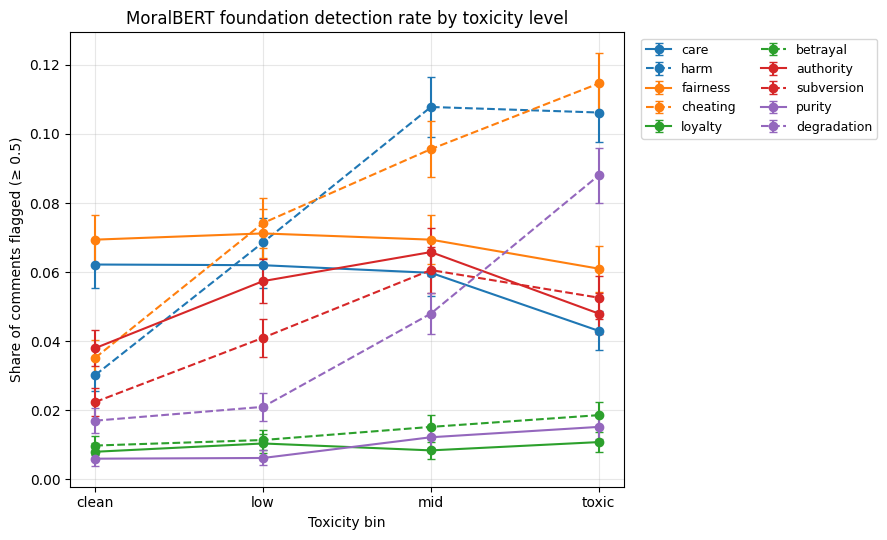

In [10]:
# plot of results from above cell, bars represent 0.95 confidence intervals
by_bin = toxicity_mb.groupby("tox_bin")[[f"mb_{m}_bin" for m in FOUNDATIONS]].mean()
by_bin.columns = FOUNDATIONS
n = toxicity_mb.groupby("tox_bin").size()

pairs = [("care", "harm"), ("fairness", "cheating"), ("loyalty", "betrayal"),
         ("authority", "subversion"), ("purity", "degradation")]
colors = plt.cm.tab10.colors

fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(by_bin))
for (virtue, vice), c in zip(pairs, colors):
    for m, style in [(virtue, "-"), (vice, "--")]:
        p = by_bin[m]
        se = np.sqrt(p * (1 - p) / n)  # binomial standard error
        ax.errorbar(x, p, yerr=1.96 * se, color=c, linestyle=style,
                    marker="o", capsize=3, label=m)

ax.set_xticks(x)
ax.set_xticklabels(by_bin.index.astype(str))
ax.set_xlabel("Toxicity bin")
ax.set_ylabel("Share of comments flagged (≥ 0.5)")
ax.set_title("MoralBERT foundation detection rate by toxicity level")
ax.legend(ncol=2, fontsize=9, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# step 4: repeat for toxicity sample data using eMFD and compare

In [11]:
!pip install -U pip setuptools wheel
!pip install -U spacy
!python -m spacy download en_core_web_sm
!pip install git+https://github.com/medianeuroscience/emfdscore.git

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 59.0 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
  Cloning https://github.com/medianeuroscience/emfdscore.git to /tmp/pip-req-build-t8wp7bi0
  Running command git clone --filter=blob:none --quiet https://github.com/medianeuroscience/emfdscore.git /tmp/pip-req-build-t8wp7bi0
  Resolved https://github.com/medianeuroscience/emfdscore.git to commit 5523d76c25afa65a59ca00e44efe45885499b116
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for emfdscore: filename=emfdscore-0.0.1-py3-none-any.whl size=1499008 sha256=b0f8d89ca53cfa16c1f

In [16]:
from emfdscore.scoring import score_docs

# eMFD expects df with text in column 0 for scoring:
docs = pd.DataFrame(toxicity_samples['comment_text'].tolist())

emfd = score_docs(docs,
                  'emfd',         # dictionary type
                  'all',          # use all five foundation probabilities per word
                  'bow',          # bag-of-words scoring
                  'vice-virtue',  # output metric (see below)
                  len(docs))

emfd.columns = ["emfd_" + c for c in emfd.columns]
emfd.index = toxicity_samples.index
toxicity_emfd = pd.concat([toxicity_samples, emfd], axis=1)
toxicity_emfd.to_csv("/content/drive/MyDrive/CS74-civilcomments/toxicity_samples_emfd.csv", index=False)

NLTK stopwords missing, downloading now.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
Processed: 20000 100% |❤❤❤❤❤❤❤❤❤❤❤❤❤❤❤❤❤❤| Elapsed Time: 0:03:11 Time:  0:03:11


In [7]:
# resume without rescoring:
toxicity_emfd = pd.read_csv("/content/drive/MyDrive/CS74-civilcomments/toxicity_samples_emfd.csv")

In [12]:
toxicity_emfd.columns

Index(['id', 'comment_text', 'split', 'created_date', 'publication_id',
       'parent_id', 'article_id', 'rating', 'funny', 'wow', 'sad', 'likes',
       'disagree', 'toxicity', 'severe_toxicity', 'obscene', 'sexual_explicit',
       'identity_attack', 'insult', 'threat', 'male', 'female', 'transgender',
       'other_gender', 'heterosexual', 'homosexual_gay_or_lesbian', 'bisexual',
       'other_sexual_orientation', 'christian', 'jewish', 'muslim', 'hindu',
       'buddhist', 'atheist', 'other_religion', 'black', 'white', 'asian',
       'latino', 'other_race_or_ethnicity', 'physical_disability',
       'intellectual_or_learning_disability', 'psychiatric_or_mental_illness',
       'other_disability', 'identity_annotator_count',
       'toxicity_annotator_count', 'tox_bin', 'emfd_care.virtue',
       'emfd_fairness.virtue', 'emfd_loyalty.virtue', 'emfd_authority.virtue',
       'emfd_sanctity.virtue', 'emfd_care.vice', 'emfd_fairness.vice',
       'emfd_loyalty.vice', 'emfd_authority.

In [15]:
# map emfd .virtue and .vice columns to matching mb names
EMFD_TO_MB = {
    "care.virtue": "care", "care.vice": "harm",
    "fairness.virtue": "fairness", "fairness.vice": "cheating",
    "loyalty.virtue": "loyalty", "loyalty.vice": "betrayal",
    "authority.virtue": "authority", "authority.vice": "subversion",
    "sanctity.virtue": "purity", "sanctity.vice": "degradation"
}

# create the renaming dictionary
rename_dict = {f"emfd_{k}": f"emfd_{v}" for k, v in EMFD_TO_MB.items()}
toxicity_emfd = toxicity_emfd.rename(columns=rename_dict)

emfd_cols = [f"emfd_{m}" for m in FOUNDATIONS]
missing = [c for c in emfd_cols if c not in toxicity_emfd.columns]
assert not missing, f"missing eMFD columns: {missing}"

both = toxicity_mb.merge(toxicity_emfd[["id"] + emfd_cols], on="id", how="inner")
# check what share of comments per foundation were scored 0 (emfd has limited dictionary), make sure this isn't alarmingly high
print("eMFD share of exact zeros:", (both[emfd_cols] == 0).mean().round(3).to_dict())

eMFD share of exact zeros: {'emfd_care': 0.155, 'emfd_harm': 0.065, 'emfd_fairness': 0.129, 'emfd_cheating': 0.076, 'emfd_loyalty': 0.096, 'emfd_betrayal': 0.1, 'emfd_authority': 0.121, 'emfd_subversion': 0.083, 'emfd_purity': 0.146, 'emfd_degradation': 0.072}


In [16]:
# overview of scoring and classification for both methods
cols = [f"mb_{m}" for m in FOUNDATIONS]
s = both[cols]

summary = pd.DataFrame({
    "mean": s.mean(),
    "median": s.median(),
    "max": s.max(),
    "share < 0.01": (s < 0.01).mean(),
    "share ≥ 0.1": (s >= 0.1).mean(),
    "share ≥ 0.5": (s >= 0.5).mean(),
    "n ≥ 0.5": (s >= 0.5).sum(),
    "unique values": s.nunique(),
})
summary.index = FOUNDATIONS
summary

,mean,median,max,share < 0.01,share ≥ 0.1,share ≥ 0.5,n ≥ 0.5,unique values
care,0.105508,0.030841,0.979260,0.08260,0.24440,0.05675,1135,19976
harm,0.085765,0.002089,0.993151,0.72985,0.13640,0.07820,1564,19970
fairness,0.073400,0.000919,0.996564,0.79745,0.11500,0.06775,1355,19963
cheating,0.087654,0.001793,0.998007,0.73615,0.13705,0.07990,1598,19973
loyalty,0.013321,0.001223,0.997424,0.93995,0.02050,0.00940,188,19927
betrayal,0.017902,0.000841,0.997705,0.92515,0.02790,0.01375,275,19964
authority,0.059394,0.001186,0.998107,0.80770,0.09640,0.05230,1046,19966
subversion,0.048549,0.001193,0.996639,0.85070,0.07510,0.04415,883,19963
purity,0.011893,0.000711,0.992018,0.96080,0.01890,0.00990,198,19940
degradation,0.069620,0.013899,0.978539,0.31890,0.12480,0.04350,870,19949


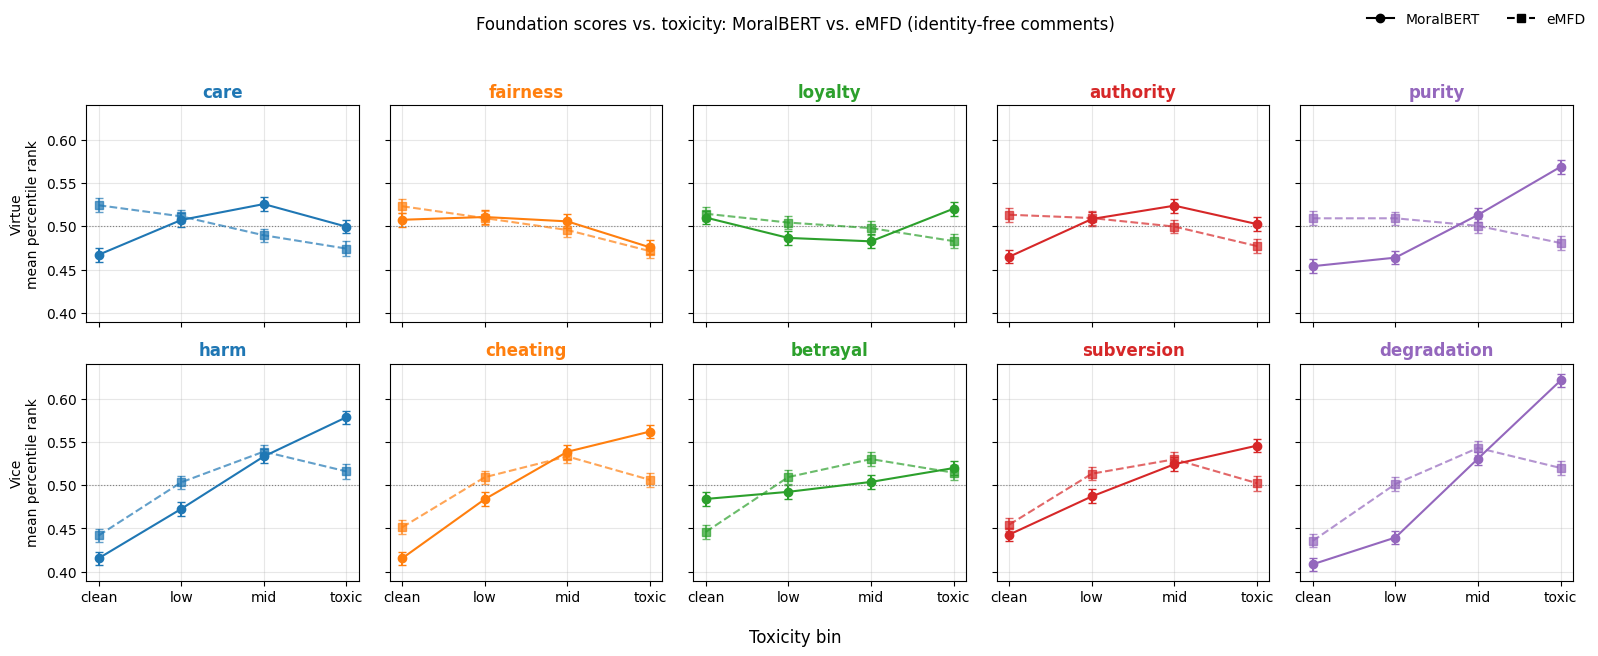

In [25]:
from matplotlib.lines import Line2D

# convert all scores into rank (i.e. this comment scores higher on care than x% of all comments in the full sample) to make emfd and mb scores comparable:
for m in FOUNDATIONS:
    both[f"mb_{m}_pct"] = both[f"mb_{m}"].rank(pct=True)
    both[f"emfd_{m}_pct"] = both[f"emfd_{m}"].rank(pct=True)

# plot rank for each foundation in each bin (averaged by bin)
pairs = [("care", "harm"), ("fairness", "cheating"), ("loyalty", "betrayal"),
         ("authority", "subversion"), ("purity", "degradation")]
colors = plt.cm.tab10.colors
tools = [("mb_", "MoralBERT", "-", "o"), ("emfd_", "eMFD", "--", "s")]
bins = sorted(both["tox_bin"].unique())
x = range(len(bins))

fig, axes = plt.subplots(2, 5, figsize=(16, 6.5), sharey=True, sharex=True)
for col, ((virtue, vice), c) in enumerate(zip(pairs, colors)):
    for row, m in enumerate([virtue, vice]):
        ax = axes[row, col]
        for tool, label, ls, marker in tools:
            g = both.groupby("tox_bin")[f"{tool}{m}_pct"]
            mean, ci = g.mean().reindex(bins), 1.96 * g.sem().reindex(bins)
            ax.errorbar(x, mean, yerr=ci, color=c, linestyle=ls, marker=marker,
                        capsize=3, alpha=1 if tool == "mb_" else 0.7)
        ax.axhline(0.5, color="gray", lw=0.8, ls=":")   # no-relationship reference at 0.5
        ax.set_title(m, color=c, fontweight="bold")
        ax.set_xticks(list(x))
        ax.set_xticklabels(bins)
        ax.grid(alpha=0.3)

axes[0, 0].set_ylabel("Virtue\nmean percentile rank")
axes[1, 0].set_ylabel("Vice\nmean percentile rank")
legend_handles = [Line2D([], [], color="black", linestyle=ls, marker=mk, label=lab)
                  for _, lab, ls, mk in tools]
fig.legend(handles=legend_handles, loc="upper right", ncol=2, frameon=False)
fig.supxlabel("Toxicity bin")
fig.suptitle("Foundation scores vs. toxicity: MoralBERT vs. eMFD (identity-free comments)")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

In [ ]:
# running scoring for identity-swap experiment data:

In [ ]:
id_sample = pd.read_csv('/content/drive/MyDrive/CS74-civilcomments/identity_samples.csv')

In [39]:
id_sample_scored = append_moralbert(id_sample, text_col='comment_text')

Scoring: care
Scoring: harm
Scoring: fairness
Scoring: cheating
Scoring: loyalty
Scoring: betrayal
Scoring: authority
Scoring: subversion
Scoring: purity
Scoring: degradation


In [41]:
id_sample_scored.to_csv("/content/drive/MyDrive/CS74-civilcomments/identity_samples_scored.csv", index=False)

In [45]:
id_swapped = pd.read_csv('/content/drive/MyDrive/CS74-civilcomments/swap_set.csv')
id_swapped_scored = append_moralbert(id_swapped, text_col='swapped_text')

Scoring: care
Scoring: harm
Scoring: fairness
Scoring: cheating
Scoring: loyalty
Scoring: betrayal
Scoring: authority
Scoring: subversion
Scoring: purity
Scoring: degradation


In [46]:
id_swapped_scored.to_csv("/content/drive/MyDrive/CS74-civilcomments/swap_set_scored.csv", index=False)

In [44]:
id_swapped.columns

Index(['id', 'group', 'pair', 'direction', 'original_text', 'swapped_text',
       'n_swaps', 'n_protected'],
      dtype='object')

In [54]:
id_swapped.sort_values(by='id', ascending=True)['original_text'].head(50)

,original_text
17657,"Not a good idea, considering that the elephant..."
17049,Or they could be moved to one of the two US sa...
24125,I have to disagree on this one! I have 3 pair...
7456,I can't believe people were ok with letting ol...
22491,That's what the craft brewing industry looks l...
7747,"I don't get your shallow take on Atheism, then..."
7737,"Okay- I rescind the slacker term in your case,..."
8113,"Hmm, it did not read like entertainment. Perh..."
8103,"Yeah, that ignorant phrase certainly does lack..."
10138,He was just a kid when he committed his crime....


In [55]:
id_sample.sort_values(by='id', ascending=True)['comment_text'].head(50)

,comment_text
31382,I think you left out one very important organi...
1607,"Not a good idea, considering that the elephant..."
31,Or they could be moved to one of the two US sa...
30556,This is what a serious mental illness looks li...
12682,I have to disagree on this one! I have 3 pair...
29718,This is what a serious mental illness looks li...
3078,I can't believe people were ok with letting ol...
31119,Part 3\nThe owner of Remedy Wine Bar (which cl...
4690,NIGGER
10939,That's what the craft brewing industry looks l...
